In [ ]:
import gc
import numpy as np
import pandas as pd

import optuna

from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

import matplotlib.pyplot as plt
import time

import joblib

from optuna.visualization import plot_optimization_history

In [ ]:
from cuml.ensemble import RandomForestRegressor
import cudf

# We use a gpu-accelerated version of RF from the cuML package

# largely mirrors the sklearn implementation, but e. g. unlike sklearn this one cannot handle nans inherently

# https://github.com/rapidsai/cuml

<h2>Methods</h2>

In [ ]:
# method to automatically downcast data types for a df
def optimize_dataframe_dtypes(df):
    df_opt = df.copy()

    for col in df_opt.columns:
        if col.startswith(("cat__", "encoded__")):
            # One-hot encoded -> int8
            df_opt[col] = df_opt[col].round().astype(np.int8)

        elif col.startswith("num__"):
            if pd.api.types.is_integer_dtype(df_opt[col]):
                df_opt[col] = pd.to_numeric(df_opt[col], downcast="integer")
            elif pd.api.types.is_float_dtype(df_opt[col]):
                df_opt[col] = pd.to_numeric(df_opt[col], downcast="float")

    return df_opt

In [ ]:
# Default sklearn parameters for comparison

default_params_rf = {
    "n_estimators": 100,  # Number of trees in the forest (more trees can reduce/increase variance, lower/increase training time)
    "max_depth": None,    # Maximum depth of the trees (None means nodes are expanded until all leaves are pure or until all leaves contain less than min_samples_split samples)
    "min_samples_split": 2,  # Minimum number of samples required to split an internal node (larger values make the model more conservative)
    "min_samples_leaf": 1,   # Minimum number of samples required to be at a leaf node (larger values prevent overfitting)
    "max_features": "auto",   # Number of features to consider when looking for the best split (can be set to 'sqrt', 'log2', or a float)
    }

In [ ]:
def objective(trial):
    print(f"Starting trial {trial.number}")

    # for memory reasons, we have to limit some of the param intervals
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 250, step=50),  
        "max_depth": trial.suggest_int("max_depth", 15, 25, step=5),       
        "min_samples_split": trial.suggest_int("min_samples_split", 4, 10),   
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 2, 4),      
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2"])
    }

    tscv = TimeSeriesSplit(n_splits=3)
    rmse_folds = []

    for fold, (train_idx, test_idx) in enumerate(tscv.split(X_train)):      
        # transform to cudf datatype for gpu acceleration  
        current_X_train = cudf.DataFrame(X_train.iloc[train_idx].astype(np.float32))
        current_X_test = cudf.DataFrame(X_train.iloc[test_idx].astype(np.float32))
        current_y_train = cudf.Series(y_train.iloc[train_idx].astype(np.float32))
        current_y_test = y_train.iloc[test_idx].astype(np.float32)

        model = RandomForestRegressor(**params)
        model.fit(current_X_train, current_y_train)

        y_pred = model.predict(current_X_test)

        fold_rmse = np.sqrt(mean_squared_error(current_y_test, y_pred))
        rmse_folds.append(fold_rmse)

        print(f"Fold {fold + 1} RMSE: {fold_rmse:.4f}")

        # Free up memory
        del model, current_X_train, current_X_test, current_y_train, current_y_test, y_pred
        gc.collect()

    avg_rmse = np.mean(rmse_folds)
    print(f"Trial {trial.number} avg RMSE: {avg_rmse:.4f}")
    return avg_rmse


<h1>Model-building (NY)</h1>

- for NY, we preprocess the data and optimize NOx models without and with lags using 20 Optuna trials and evaluate it by training with 2019-2023 data and testing on 2024 data five separate times and taking the average performance
- ran into problems with memory which is why data is downsampled and studies are manually resumed if a study crashed midway through (-> studies were run up to 20 successful trials)

In [ ]:
campd_type_dict = {
    'State': 'string',
    'Facility Name': 'string',
    'Facility ID': 'Int32',
    'Unit ID': 'string',
    'Hour': 'Int8',
    'Operating Time': 'float32',
    'Gross Load (MW)': 'float32',
    'Steam Load (1000 lb/hr)': 'float32',
    'SO2 Mass (lbs)': 'float64',
    'SO2 Mass Measure Indicator': 'string',
    'SO2 Rate (lbs/mmBtu)': 'float32',
    'SO2 Rate Measure Indicator': 'string',
    'CO2 Mass (short tons)': 'float32',
    'CO2 Mass Measure Indicator': 'string',
    'CO2 Rate (short tons/mmBtu)': 'float32',
    'CO2 Rate Measure Indicator': 'string',
    'NOx Mass (lbs)': 'float32',
    'NOx Mass Measure Indicator': 'string',
    'NOx Rate (lbs/mmBtu)': 'float32',
    'NOx Rate Measure Indicator': 'string',
    'Heat Input (mmBtu)': 'float64',
    'Heat Input Measure Indicator': 'string',
    'Primary Fuel Type': 'string',
    'Secondary Fuel Type': 'string',
    'Unit Type': 'string',
    'SO2 Controls': 'string',
    'NOx Controls': 'string',
    'Program Code': 'string',
    'Year': 'int16',
    'Source Category': 'string',
    'Latitude': 'float32',
    'Longitude': 'float32',
    'SO2 Phase': 'string',
    'NOx Phase': 'string',
    'Operating Status': 'string',
    'Max Hourly HI Rate (mmBtu/hr)': 'float32',
    'Associated Generators & Nameplate Capacity (MWe)': 'string',
    'Nameplate Capacity (MWe)': 'float32',
    'Month': 'Int8',
    'hourly_capacity_factor': 'float32',
    'hourly_ramping_factor': 'float32',
    'Nameplate Capacity (MW) - EIA': 'float32',
    'Summer Capacity (MW)': 'float32',
    'Winter Capacity (MW)': 'float32',
    'Minimum Load (MW)': 'float32',
    'Operating Year_min': 'float32',
    'Operating Year_max': 'float32',
    'Operating Year_mean': 'float32',
    'Planned Retirement Year': 'Int16',
    'unit_age_min': 'Int8',
    'unit_age_max': 'Int8',
    'unit_age_mean': 'float32',
    'Day': 'float32',
    'Temperature (F)': 'float32'
}

<h2>No Lags</h2>

<h3>NOx</h3>

<h4>Preprocessing</h4>

In [6]:
campd_df = pd.read_csv("Data/NY/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [7]:
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) 

target_variable = "NOx Mass (lbs)"

In [14]:
navals = campd_df[num_features + encoded_cat_features + unencoded_cat_features].isna().sum() / len(campd_df) * 100
navals[navals > 0]

# instead of imputing with median, we remove nan cols/rows (Summer Capacity has too many nans to impute, for lower nan values we remove the rows)

# (data is highly skewed, so simple median imputation would likely be problematic)

Gross Load (MW)              4.674485
Latitude                    11.055066
Longitude                   11.055066
Nameplate Capacity (MWe)    11.055066
hourly_capacity_factor       5.678980
hourly_ramping_factor       15.730771
Summer Capacity (MW)        59.033506
Winter Capacity (MW)        59.033506
Minimum Load (MW)           59.033506
Temperature (F)              1.723858
dtype: float64

In [17]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3197828, 95), New shape: (2666036, 95)
Change in total rows: -531792


In [10]:
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                #'Summer Capacity (MW)',
                #'Winter Capacity (MW)', 
                #'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [11]:
X_train = optimize_dataframe_dtypes(X_train)
X_test = optimize_dataframe_dtypes(X_test)

In [12]:
# Sample while keeping the original time order (just doing .sample() shuffles order)
sample_indices = X_train.sample(frac=0.2, random_state=42).index
X_train_sampled = X_train.loc[X_train.index.isin(sample_indices)]
y_train_sampled = y_train.loc[y_train.index.isin(sample_indices)]

In [24]:
import pandas as pd
import numpy as np

# Create an ordered time-series DataFrame
X_train = pd.DataFrame(
    {'value': range(10)},
    index=pd.to_datetime(['2025-01-01', '2025-01-02', '2025-01-03', '2025-01-04', '2025-01-05',
                           '2025-01-06', '2025-01-07', '2025-01-08', '2025-01-09', '2025-01-10'])
)

print("--- Original Ordered X_train ---")
print(X_train)

# Your method: sample the index
sample_indices = X_train.sample(frac=0.5, random_state=42).index
print("\n--- The Sampled Indices (Shuffled Order) ---")
print(sample_indices)


# Filter using .loc
X_train_sampled = X_train.loc[sample_indices]
print("\n--- Resulting DataFrame (Order is Broken) ---")
print(X_train_sampled)


X_train_sampled = X_train.loc[X_train.index.isin(sample_indices)]
print("\n--- Resulting DataFrame (Order is Kept) ---")
print(X_train_sampled)

--- Original Ordered X_train ---
            value
2025-01-01      0
2025-01-02      1
2025-01-03      2
2025-01-04      3
2025-01-05      4
2025-01-06      5
2025-01-07      6
2025-01-08      7
2025-01-09      8
2025-01-10      9

--- The Sampled Indices (Shuffled Order) ---
DatetimeIndex(['2025-01-09', '2025-01-02', '2025-01-06', '2025-01-01',
               '2025-01-08'],
              dtype='datetime64[ns]', freq=None)

--- Resulting DataFrame (Order is Broken) ---
            value
2025-01-09      8
2025-01-02      1
2025-01-06      5
2025-01-01      0
2025-01-08      7

--- Resulting DataFrame (Order is Broken) ---
            value
2025-01-01      0
2025-01-02      1
2025-01-06      5
2025-01-08      7
2025-01-09      8


<h4>HPO</h4>

In [ ]:
study = optuna.create_study(
    study_name="02_08_11_30_RF_NY_NOx",
    storage="sqlite:///optuna_studies.db",
    direction="minimize",
    load_if_exists=True
)
study.optimize(objective, n_trials=20) 

print("Best trial:")
print(study.best_trial.params)

In [13]:
# Load best parameters from Optuna
study = optuna.load_study(
    study_name="02_08_11_30_RF_NY_NOx",
    storage="sqlite:///optuna_studies.db"
)
best_params = study.best_trial.params

# best params found
hpo_params = {
    **study.best_params    
}

print("Best params:", study.best_params)
print("Best value (RMSE):", study.best_value)

Best params: {'n_estimators': 100, 'max_depth': 25, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 'sqrt'}
Best value (RMSE): 15.345575295381826


<h4>Evaluation</h4>

In [ ]:
best_r2 = -np.inf
best_model = None
best_y_pred = None
best_y_test = None

for i in range(5):
    print(f"\nTraining iteration {i + 1}")

    model = RandomForestRegressor(random_state=i, **hpo_params)
    model.fit(X_train_sampled, y_train_sampled)

    y_pred = model.predict(X_test)
    y_pred[y_pred < 0] = 0  

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    nrmse = rmse/np.std(y_test)

    print(f"R²: {r2:.4f} | MSE: {mse:.4f} | RMSE: {rmse:.4f} | nRMSE: {nrmse:.4f}")

    if r2 > best_r2:
        best_model = model
        best_r2 = r2

joblib.dump(best_model, "Trained Models/RF_HPO_NY_NOx_No_Lags.pkl")


Training iteration 1
R²: 0.9634 | MSE: 146.3094 | RMSE: 12.0958 | nRMSE: 0.1911

Training iteration 2
R²: 0.9647 | MSE: 141.2049 | RMSE: 11.8830 | nRMSE: 0.1877

Training iteration 3
R²: 0.9646 | MSE: 141.7315 | RMSE: 11.9051 | nRMSE: 0.1881

Training iteration 4
R²: 0.9656 | MSE: 137.6415 | RMSE: 11.7321 | nRMSE: 0.1853

Training iteration 5
R²: 0.9641 | MSE: 143.7997 | RMSE: 11.9917 | nRMSE: 0.1894


['Trained Models/RF_HPO_NY_NOx_No_Lags.pkl']

In [2]:
r2_scores = np.array([0.9634, 0.9647, 0.9646, 0.9656, 0.9641])
mse_values = np.array([146.3094, 141.2049, 141.7315, 137.6415, 143.7997])
rmse_values = np.array([12.0958, 11.8830, 11.9051, 11.7321, 11.9917])
nrmse_values = np.array([0.1911, 0.1877, 0.1881, 0.1853, 0.1894])

print(f"R2: {np.mean(r2_scores):.4f}")
print(f"MSE: {np.mean(mse_values):.4f}")
print(f"RMSE: {np.mean(rmse_values):.4f}")
print(f"nRMSE: {np.mean(nrmse_values):.4f}")

R2: 0.9645
MSE: 142.1374
RMSE: 11.9215
nRMSE: 0.1883


<h3>SO2</h3>

<h4>Preprocessing</h4>

In [6]:
campd_df = pd.read_csv("Data/NY/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [7]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'SO2 Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type', 'SO2 Controls'] 

encoded_cat_features = list(df_code_cols) 

target_variable = "SO2 Mass (lbs)"

In [23]:
navals = campd_df[num_features + encoded_cat_features + unencoded_cat_features].isna().sum() / len(campd_df) * 100
navals[navals > 0]

# instead of imputing with median, we remove nan cols/rows (Summer Capacity has too many nans to impute, for lower nan values we remove the rows)

# (data is highly skewed, so simple median imputation would likely be problematic)

Gross Load (MW)              5.967985
Latitude                    10.302394
Longitude                   10.302394
Nameplate Capacity (MWe)    10.302394
hourly_capacity_factor       6.935827
hourly_ramping_factor       16.271541
Summer Capacity (MW)        58.785922
Winter Capacity (MW)        58.785922
Minimum Load (MW)           58.785922
Temperature (F)              1.696861
dtype: float64

In [8]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3443122, 80), New shape: (2850950, 80)
Change in total rows: -592172


In [9]:
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                #'Summer Capacity (MW)',
                #'Winter Capacity (MW)', 
                #'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [10]:
X_train = optimize_dataframe_dtypes(X_train)
X_test = optimize_dataframe_dtypes(X_test)

In [11]:
# Sample while keeping the original time order (just doing .sample() shuffles order)
sample_indices = X_train.sample(frac=0.2, random_state=42).index
X_train_sampled = X_train.loc[X_train.index.isin(sample_indices)]
y_train_sampled = y_train.loc[y_train.index.isin(sample_indices)]

<h4>HPO</h4>

In [ ]:
study = optuna.create_study(
    study_name="02_08_11_50_RF_NY_SO2",
    storage="sqlite:///optuna_studies.db",
    direction="minimize",
    load_if_exists=True
)
study.optimize(objective, n_trials=20) 

print("Best trial:")
print(study.best_trial.params)

In [12]:
# Load best parameters from Optuna
study = optuna.load_study(
    study_name="02_08_11_50_RF_NY_SO2",
    storage="sqlite:///optuna_studies.db"
)
best_params = study.best_trial.params

# best params found
hpo_params = {
    **study.best_params,
    
}

print("Best params:", study.best_params)
print("Best value (RMSE):", study.best_value)

Best params: {'n_estimators': 150, 'max_depth': 25, 'min_samples_split': 7, 'min_samples_leaf': 2, 'max_features': 'sqrt'}
Best value (RMSE): 53.42953512511277


<h4>Evaluation</h4>

In [ ]:
best_r2 = -np.inf
best_model = None
best_y_pred = None
best_y_test = None

for i in range(5):
    print(f"\nTraining iteration {i + 1}")

    model = RandomForestRegressor(random_state=i, **hpo_params)
    model.fit(X_train_sampled, y_train_sampled)

    y_pred = model.predict(X_test)
    y_pred[y_pred < 0] = 0  

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    nrmse = rmse/np.std(y_test)

    print(f"R²: {r2:.4f} | MSE: {mse:.4f} | RMSE: {rmse:.4f} | nRMSE: {nrmse:.4f}")

    if r2 > best_r2:
        best_model = model
        best_r2 = r2

joblib.dump(best_model, "Trained Models/RF_HPO_NY_SO2_No_Lags.pkl")


Training iteration 1
R²: 0.7324 | MSE: 822.5363 | RMSE: 28.6799 | nRMSE: 0.5173

Training iteration 2
R²: 0.7277 | MSE: 837.0545 | RMSE: 28.9319 | nRMSE: 0.5218

Training iteration 3
R²: 0.7284 | MSE: 834.9713 | RMSE: 28.8959 | nRMSE: 0.5212

Training iteration 4
R²: 0.7282 | MSE: 835.4549 | RMSE: 28.9042 | nRMSE: 0.5213

Training iteration 5
R²: 0.7271 | MSE: 838.9924 | RMSE: 28.9654 | nRMSE: 0.5224


['Trained Models/RF_HPO_NY_SO2_No_Lags.pkl']

In [3]:
r2_scores = np.array([0.7324, 0.7277, 0.7284, 0.7282, 0.7271])
mse_values = np.array([822.5363, 837.0545, 834.9713, 835.4549, 838.9924])
rmse_values = np.array([28.6799, 28.9319, 28.8959, 28.9042, 28.9654])
nrmse_values = np.array([0.5173, 0.5218, 0.5212, 0.5213, 0.5224])

print(f"R2: {np.mean(r2_scores):.4f}")
print(f"MSE: {np.mean(mse_values):.4f}")
print(f"RMSE: {np.mean(rmse_values):.4f}")
print(f"nRMSE: {np.mean(nrmse_values):.4f}")

R2: 0.7288
MSE: 833.8019
RMSE: 28.8755
nRMSE: 0.5208


<h3>CO2</h3>

<h4>Preprocessing</h4>

In [6]:
campd_df = pd.read_csv("Data/NY/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [7]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_code_cols) 

target_variable = "CO2 Mass (short tons)"

In [8]:
navals = campd_df[num_features + encoded_cat_features + unencoded_cat_features].isna().sum() / len(campd_df) * 100
navals[navals > 0]

# instead of imputing with median, we remove nan cols/rows (Summer Capacity has too many nans to impute, for lower nan values we remove the rows)

# (data is highly skewed, so simple median imputation would likely be problematic)

Gross Load (MW)              5.967985
Latitude                    10.302394
Longitude                   10.302394
Nameplate Capacity (MWe)    10.302394
hourly_capacity_factor       6.935827
hourly_ramping_factor       16.271541
Summer Capacity (MW)        58.785922
Winter Capacity (MW)        58.785922
Minimum Load (MW)           58.785922
Temperature (F)              1.696861
dtype: float64

In [8]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3414203, 80), New shape: (2822490, 80)
Change in total rows: -591713


In [9]:
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                #'Summer Capacity (MW)',
                #'Winter Capacity (MW)', 
                #'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [10]:
X_train = optimize_dataframe_dtypes(X_train)
X_test = optimize_dataframe_dtypes(X_test)

In [12]:
# Sample while keeping the original time order (just doing .sample() shuffles order)
sample_indices = X_train.sample(frac=0.2, random_state=42).index
X_train_sampled = X_train.loc[X_train.index.isin(sample_indices)]
y_train_sampled = y_train.loc[y_train.index.isin(sample_indices)]

<h4>HPO</h4>

In [ ]:
study = optuna.create_study(
    study_name="02_08_12_15_RF_NY_CO2",
    storage="sqlite:///optuna_studies.db",
    direction="minimize",
    load_if_exists=True
)
study.optimize(objective, n_trials=20) 

print("Best trial:")
print(study.best_trial.params)

In [14]:
# Load best parameters from Optuna
study = optuna.load_study(
    study_name="02_08_12_15_RF_NY_CO2",
    storage="sqlite:///optuna_studies.db"
)
best_params = study.best_trial.params

# best params found
hpo_params = {
    **study.best_params    
}

print("Best params:", study.best_params)
print("Best value (RMSE):", study.best_value)

Best params: {'n_estimators': 200, 'max_depth': 25, 'min_samples_split': 4, 'min_samples_leaf': 4, 'max_features': 'sqrt'}
Best value (RMSE): 4.39287813834384


<h4>Evaluation</h4>

In [ ]:
best_r2 = -np.inf
best_model = None
best_y_pred = None
best_y_test = None

for i in range(5):
    print(f"\nTraining iteration {i + 1}")

    model = RandomForestRegressor(random_state=i, **hpo_params)
    model.fit(X_train_sampled, y_train_sampled)

    y_pred = model.predict(X_test)
    y_pred[y_pred < 0] = 0  

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    nrmse = rmse/np.std(y_test)

    print(f"R²: {r2:.4f} | MSE: {mse:.4f} | RMSE: {rmse:.4f} | nRMSE: {nrmse:.4f}")

    if r2 > best_r2:
        best_model = model
        best_r2 = r2

joblib.dump(best_model, "Trained Models/RF_HPO_NY_CO2_No_Lags.pkl")


Training iteration 1
R²: 0.9962 | MSE: 12.1880 | RMSE: 3.4911 | nRMSE: 0.0618

Training iteration 2
R²: 0.9963 | MSE: 11.8857 | RMSE: 3.4476 | nRMSE: 0.0610

Training iteration 3
R²: 0.9966 | MSE: 10.7862 | RMSE: 3.2842 | nRMSE: 0.0581

Training iteration 4
R²: 0.9962 | MSE: 12.1386 | RMSE: 3.4840 | nRMSE: 0.0616

Training iteration 5
R²: 0.9961 | MSE: 12.3216 | RMSE: 3.5102 | nRMSE: 0.0621


['Trained Models/RF_HPO_NY_CO2_No_Lags.pkl']

In [4]:
r2_scores = np.array([0.9962, 0.9963, 0.9966, 0.9962, 0.9961])
mse_values = np.array([12.1880, 11.8857, 10.7862, 12.1386, 12.3216])
rmse_values = np.array([3.4911, 3.4476, 3.2842, 3.4840, 3.5102])
nrmse_values = np.array([0.0618, 0.0610, 0.0581, 0.0616, 0.0621])

print(f"R2: {np.mean(r2_scores):.4f}")
print(f"MSE: {np.mean(mse_values):.4f}")
print(f"RMSE: {np.mean(rmse_values):.4f}")
print(f"nRMSE: {np.mean(nrmse_values):.4f}")

R2: 0.9963
MSE: 11.8640
RMSE: 3.4434
nRMSE: 0.0609


<h2>With Lags</h2>

<h3>NOx</h3>

<h4>Preprocessing</h4>

In [6]:
campd_df = pd.read_csv("Data/NY/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [7]:
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) 

target_variable = "NOx Mass (lbs)"

In [8]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3197828, 95), New shape: (2666036, 95)
Change in total rows: -531792


In [9]:
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                #'Summer Capacity (MW)',
                #'Winter Capacity (MW)', 
                #'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ] + lag_cols

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [10]:
X_train = X_train.dropna(axis=0, how='any')  # drop lag rows with nan
y_train = y_train[X_train.index]  # align y_train with X_train after dropping NaN rows

In [11]:
X_train = optimize_dataframe_dtypes(X_train)
X_test = optimize_dataframe_dtypes(X_test)

In [12]:
# Sample while keeping the original time order (just doing .sample() shuffles order)
sample_indices = X_train.sample(frac=0.2, random_state=42).index
X_train_sampled = X_train.loc[X_train.index.isin(sample_indices)]
y_train_sampled = y_train.loc[y_train.index.isin(sample_indices)]

<h4>HPO</h4>

In [ ]:
study = optuna.create_study(
    study_name="02_08_16_00_RF_NY_NOx_WITH_LAGS",
    storage="sqlite:///optuna_studies.db",
    #load_if_exists=True,
    direction="minimize"
)
study.optimize(objective, n_trials=20) 

print("Best trial:")
print(study.best_trial.params)

In [ ]:
# Load best parameters from Optuna
study = optuna.load_study(
    study_name="02_08_16_00_RF_NY_NOx_WITH_LAGS",
    storage="sqlite:///optuna_studies.db"
)
best_params = study.best_trial.params

# best params found
hpo_params = {
    **study.best_params    
}


<h4>Evaluation</h4>

In [ ]:
best_r2 = -np.inf
best_model = None
best_y_pred = None
best_y_test = None

for i in range(5):
    print(f"\nTraining iteration {i + 1}")

    model = RandomForestRegressor(random_state=i, **hpo_params)
    model.fit(X_train_sampled, y_train_sampled)

    y_pred = model.predict(X_test)
    y_pred[y_pred < 0] = 0  

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    nrmse = rmse/np.std(y_test)

    print(f"R²: {r2:.4f} | MSE: {mse:.4f} | RMSE: {rmse:.4f} | nRMSE: {nrmse:.4f}")

    if r2 < best_r2:
        best_model = model
        best_r2 = r2

joblib.dump(best_model, "Trained Models/RF_HPO_NY_NOx_With_Lags.pkl")


Training iteration 1
R²: 0.9698 | MSE: 120.9843 | RMSE: 10.9993 | nRMSE: 0.1738

Training iteration 2
R²: 0.9714 | MSE: 114.2910 | RMSE: 10.6907 | nRMSE: 0.1689

Training iteration 3
R²: 0.9715 | MSE: 113.9458 | RMSE: 10.6745 | nRMSE: 0.1686

Training iteration 4
R²: 0.9708 | MSE: 116.8059 | RMSE: 10.8077 | nRMSE: 0.1707

Training iteration 5
R²: 0.9719 | MSE: 112.4547 | RMSE: 10.6045 | nRMSE: 0.1675


['Trained Models/RF_HPO_NY_NOx_With_Lags.pkl']

In [4]:
r2_scores = np.array([0.9698, 0.9714, 0.9715, 0.9708, 0.9719])
mse_values = np.array([120.9843, 114.2910, 113.9458, 116.8059, 112.4547])
rmse_values = np.array([10.9993, 10.6907, 10.6745, 10.8077, 10.6045])
nrmse_values = np.array([0.1738, 0.1689, 0.1686, 0.1707, 0.1675])

print(f"Average R2: {np.mean(r2_scores):.4f}")
print(f"Average MSE: {np.mean(mse_values):.4f}")
print(f"Average RMSE: {np.mean(rmse_values):.4f}")
print(f"Average nRMSE: {np.mean(nrmse_values):.4f}")


Average R2: 0.9711
Average MSE: 115.6963
Average RMSE: 10.7553
Average nRMSE: 0.1699


R^2 Score: 0.9719
Mean Squared Error (MSE): 112.4547
Root Mean Squared Error (RMSE): 10.6045
Normalized Root Mean Squared Error (nRMSE): 0.1675


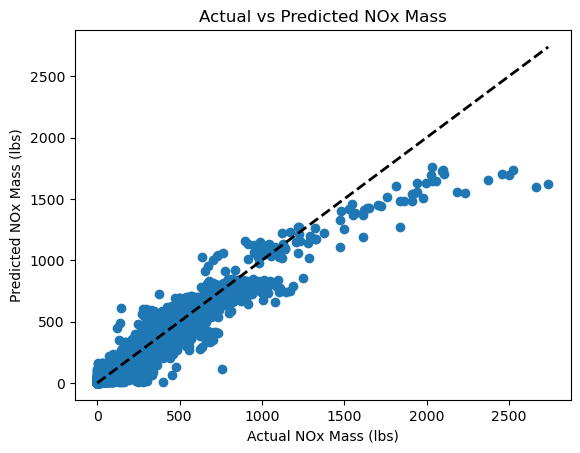

In [16]:
best_model = joblib.load("Trained Models/RF_HPO_NY_NOx_With_Lags.pkl")

y_pred = best_model.predict(X_test)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized Root Mean Squared Error (nRMSE): {np.sqrt(mean_squared_error(y_test, y_pred))/np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h3>SO2</h3>

<h4>Preprocessing</h4>

In [6]:
campd_df = pd.read_csv("Data/NY/SO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [7]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ] + lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'SO2 Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type', 'SO2 Controls'] 

encoded_cat_features = list(df_code_cols) 

target_variable = "SO2 Mass (lbs)"

In [8]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3443122, 80), New shape: (2850950, 80)
Change in total rows: -592172


In [9]:
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                #'Summer Capacity (MW)',
                #'Winter Capacity (MW)', 
                #'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ] + lag_cols

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["SO2 Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [10]:
X_train = X_train.dropna(axis=0, how='any')  # drop lag rows with nan
y_train = y_train[X_train.index]  # align y_train with X_train after dropping NaN rows

In [11]:
X_train = optimize_dataframe_dtypes(X_train)
X_test = optimize_dataframe_dtypes(X_test)

In [12]:
# Sample while keeping the original time order (just doing .sample() shuffles order)
sample_indices = X_train.sample(frac=0.2, random_state=42).index
X_train_sampled = X_train.loc[X_train.index.isin(sample_indices)]
y_train_sampled = y_train.loc[y_train.index.isin(sample_indices)]

<h4>HPO</h4>

In [ ]:
study = optuna.create_study(
    study_name="02_08_16_45_RF_NY_SO2_WITH_LAGS",
    storage="sqlite:///optuna_studies.db",
    #load_if_exists=True,
    direction="minimize"
)
study.optimize(objective, n_trials=20) 

print("Best trial:")
print(study.best_trial.params)

In [ ]:
# Load best parameters from Optuna
study = optuna.load_study(
    study_name="02_08_16_45_RF_NY_SO2_WITH_LAGS",
    storage="sqlite:///optuna_studies.db"
)
best_params = study.best_trial.params

# best params found
hpo_params = {
    **study.best_params    
}


<h4>Evaluation</h4>

In [ ]:
best_r2 = -np.inf
best_model = None
best_y_pred = None
best_y_test = None

for i in range(5):
    print(f"\nTraining iteration {i + 1}")

    model = RandomForestRegressor(random_state=i, **hpo_params)
    model.fit(X_train_sampled, y_train_sampled)

    y_pred = model.predict(X_test)
    y_pred[y_pred < 0] = 0  

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    nrmse = rmse/np.std(y_test)

    print(f"R²: {r2:.4f} | MSE: {mse:.4f} | RMSE: {rmse:.4f} | nRMSE: {nrmse:.4f}")

    if r2 < best_r2:
        best_model = model
        best_r2 = r2

joblib.dump(best_model, "Trained Models/RF_HPO_NY_SO2_With_Lags.pkl")


Training iteration 1
R²: 0.9054 | MSE: 290.8555 | RMSE: 17.0545 | nRMSE: 0.3076

Training iteration 2
R²: 0.9016 | MSE: 302.5804 | RMSE: 17.3948 | nRMSE: 0.3137

Training iteration 3
R²: 0.9007 | MSE: 305.2109 | RMSE: 17.4703 | nRMSE: 0.3151

Training iteration 4
R²: 0.9030 | MSE: 298.2616 | RMSE: 17.2703 | nRMSE: 0.3115

Training iteration 5
R²: 0.8992 | MSE: 309.8603 | RMSE: 17.6028 | nRMSE: 0.3175


['Trained Models/RF_HPO_NY_SO2_With_Lags.pkl']

In [16]:
r2_scores = np.array([0.9054, 0.9016, 0.9007, 0.9030, 0.8992])
mse_values = np.array([290.8555, 302.5804, 305.2109, 298.2616, 309.8603])
rmse_values = np.array([17.0545, 17.3948, 17.4703, 17.2703, 17.6028])
nrmse_values = np.array([0.3076, 0.3137, 0.3151, 0.3115, 0.3175])

print(f"R2: {np.mean(r2_scores):.4f}")
print(f"MSE: {np.mean(mse_values):.4f}")
print(f"RMSE: {np.mean(rmse_values):.4f}")
print(f"nRMSE: {np.mean(nrmse_values):.4f}")

# bad performance e. g. possibly due to how missing values are handled

R2: 0.9020
MSE: 301.3537
RMSE: 17.3585
nRMSE: 0.3131


R^2 Score: 0.9054
Mean Squared Error (MSE): 290.8555
Root Mean Squared Error (RMSE): 17.0545
Normalized Root Mean Squared Error (nRMSE): 0.3076


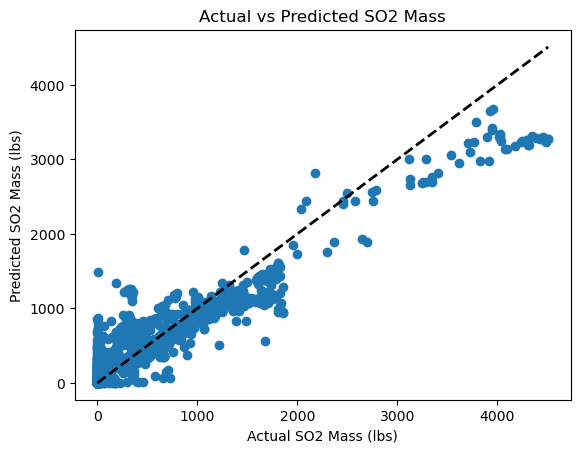

In [15]:
best_model = joblib.load("Trained Models/RF_HPO_NY_SO2_With_Lags.pkl")

y_pred = best_model.predict(X_test)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized Root Mean Squared Error (nRMSE): {np.sqrt(mean_squared_error(y_test, y_pred))/np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual SO2 Mass (lbs)")
plt.ylabel("Predicted SO2 Mass (lbs)")
plt.title("Actual vs Predicted SO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h3>CO2</h3>

<h4>Preprocessing</h4>

In [6]:
campd_df = pd.read_csv("Data/NY/CO2/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [7]:
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ] + lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_code_cols) 

target_variable = "CO2 Mass (short tons)"

In [8]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3414203, 80), New shape: (2822490, 80)
Change in total rows: -591713


In [9]:
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                #'Summer Capacity (MW)',
                #'Winter Capacity (MW)', 
                #'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ] + lag_cols

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [10]:
X_train = X_train.dropna(axis=0, how='any')  # drop lag rows with nan
y_train = y_train[X_train.index]  # align y_train with X_train after dropping NaN rows

In [11]:
X_train = optimize_dataframe_dtypes(X_train)
X_test = optimize_dataframe_dtypes(X_test)

In [12]:
# Sample while keeping the original time order (just doing .sample() shuffles order)
sample_indices = X_train.sample(frac=0.2, random_state=42).index
X_train_sampled = X_train.loc[X_train.index.isin(sample_indices)]
y_train_sampled = y_train.loc[y_train.index.isin(sample_indices)]

<h4>HPO</h4>

In [ ]:
study = optuna.create_study(
    study_name="02_08_17_30_RF_NY_CO2_WITH_LAGS",
    storage="sqlite:///optuna_studies.db",
    #load_if_exists=True,
    direction="minimize"
)
study.optimize(objective, n_trials=20) 

print("Best trial:")
print(study.best_trial.params)

In [ ]:
# Load best parameters from Optuna
study = optuna.load_study(
    study_name="02_08_17_30_RF_NY_CO2_WITH_LAGS",
    storage="sqlite:///optuna_studies.db"
)
best_params = study.best_trial.params

# best params found
hpo_params = {
    **study.best_params    
}

<h4>Evaluation</h4>

In [ ]:
best_r2 = -np.inf
best_model = None
best_y_pred = None
best_y_test = None

for i in range(5):
    print(f"\nTraining iteration {i + 1}")

    model = RandomForestRegressor(random_state=i, **hpo_params)
    model.fit(X_train_sampled, y_train_sampled)

    y_pred = model.predict(X_test)
    y_pred[y_pred < 0] = 0  

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    nrmse = rmse/np.std(y_test)

    print(f"R²: {r2:.4f} | MSE: {mse:.4f} | RMSE: {rmse:.4f} | nRMSE: {nrmse:.4f}")

    if r2 < best_r2:
        best_model = model
        best_r2 = r2

joblib.dump(best_model, "Trained Models/RF_HPO_NY_CO2_With_Lags.pkl")


Training iteration 1
R²: 0.9972 | MSE: 8.9728 | RMSE: 2.9955 | nRMSE: 0.0530

Training iteration 2
R²: 0.9973 | MSE: 8.6109 | RMSE: 2.9344 | nRMSE: 0.0519

Training iteration 3
R²: 0.9973 | MSE: 8.4634 | RMSE: 2.9092 | nRMSE: 0.0515

Training iteration 4
R²: 0.9974 | MSE: 8.4306 | RMSE: 2.9035 | nRMSE: 0.0514

Training iteration 5
R²: 0.9972 | MSE: 8.8358 | RMSE: 2.9725 | nRMSE: 0.0526


['Trained Models/RF_HPO_NY_CO2_With_Lags.pkl']

In [16]:
r2_scores = np.array([0.9972, 0.9973, 0.9973, 0.9974, 0.9972])
mse_values = np.array([8.9728, 8.6109, 8.4634, 8.4306, 8.8358])
rmse_values = np.array([2.9955, 2.9344, 2.9092, 2.9035, 2.9725])
nrmse_values = np.array([0.0530, 0.0519, 0.0515, 0.0514, 0.0526])

print(f"R2: {np.mean(r2_scores):.4f}")
print(f"MSE: {np.mean(mse_values):.4f}")
print(f"RMSE: {np.mean(rmse_values):.4f}")
print(f"nRMSE: {np.mean(nrmse_values):.4f}")

R2: 0.9973
MSE: 8.6627
RMSE: 2.9430
nRMSE: 0.0521


R^2 Score: 0.9974
Mean Squared Error (MSE): 8.4306
Root Mean Squared Error (RMSE): 2.9035
Normalized Root Mean Squared Error (nRMSE): 0.0514


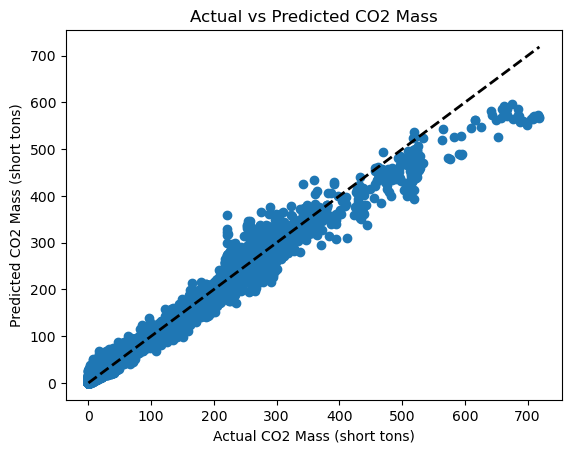

In [15]:
best_model = joblib.load("Trained Models/RF_HPO_NY_CO2_With_Lags.pkl")

y_pred = best_model.predict(X_test)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized Root Mean Squared Error (nRMSE): {np.sqrt(mean_squared_error(y_test, y_pred))/np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h2>Visualizations</h2>

- some selected optuna history plots of optimizations (show value of objective function across studies -> RMSE)
- note that trials numbers can exceed 20 if previous ones crashed due to memory issues. total of successful trials always sums up to 20 though.

In [ ]:
# NOx no lags

study = optuna.load_study(
    study_name="02_08_11_30_RF_NY_NOx",
    storage="sqlite:///optuna_studies.db"
)

opt_history = plot_optimization_history(study)
opt_history.show()

no_of_trials = 0
for trial in study.trials:
    if trial.state == 1:
        no_of_trials += 1

print(f"Number of successfully completed trials: {no_of_trials}")

Number of successfully completed trials: 20


In [ ]:
# SO2 no lags
study = optuna.load_study(
    study_name="02_08_11_50_RF_NY_SO2",
    storage="sqlite:///optuna_studies.db"
)

opt_history = plot_optimization_history(study)
opt_history.show()

In [ ]:
# CO2 no lags

study = optuna.load_study(
    study_name="02_08_12_15_RF_NY_CO2",
    storage="sqlite:///optuna_studies.db"
)
opt_history = plot_optimization_history(study)
opt_history.show()